# 4. Calibrating Heston and Merton
Black-Scholes uses one vol for every option, so it can't produce the skew and term structure from notebook 3. Here I fit two models that can: Heston (volatility is itself random, and correlated with the price) and Merton (Black-Scholes plus sudden jumps). I fit each to 480 options and test it on the other 2,698 options it never saw.

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, quad_vec
from scipy.stats import norm, poisson
from scipy.optimize import brentq, least_squares

options = pd.read_csv("spy_surface_clean_2026-10-08.csv")
forwards = pd.read_csv("spy_forwards_2026-10-08.csv")
options["expiry"] = pd.to_datetime(options["expiry"])
forwards["expiry"] = pd.to_datetime(forwards["expiry"])
print(options.shape, forwards.shape)

(3178, 21) (24, 6)


The Black-76 pricer and implied vol solver from notebook 2. Every model price gets turned back into an implied vol with these, so I can compare models in vol points.

In [2]:
def bs_price(F, K, T, r, sigma, option_type):
    D = np.exp(-r * T)
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return D * (F * norm.cdf(d1) - K * norm.cdf(d2))
    else:
        return D * (K * norm.cdf(-d2) - F * norm.cdf(-d1))


def implied_vol(price, F, K, T, r, option_type):
    D = np.exp(-r * T)
    # no-arbitrage bounds: the prices sigma = 0 and sigma = infinity give
    if option_type == "call":
        lower = D * max(F - K, 0)
        upper = D * F
    else:
        lower = D * max(K - F, 0)
        upper = D * K
    if price <= lower or price >= upper:
        return np.nan
    def gap(sigma):
        return bs_price(F, K, T, r, sigma, option_type) - price
    try:
        return brentq(gap, 0.0001, 5.0)
    except ValueError:
        return np.nan

## Heston
In Heston the variance v follows its own random process: it is pulled back towards a long-run level θ at speed κ, its own volatility is ξ ("vol of vol"), and its shocks are correlated with the price shocks by ρ. v0 is today's variance.

There is no closed-form price, but the characteristic function of ln(F_T) is known in closed form. Prices come from two integrals of it, P1 and P2, which play the roles of N(d1) and N(d2) in Black-Scholes. I use the "little Heston trap" form of the characteristic function (Albrecher et al.), which avoids a jump in the complex logarithm at long maturities.

In [3]:
def heston_cf(u, T, v0, kappa, theta, xi, rho):
    # E[exp(iu x)] with x = ln(F_T / F)
    iu = 1j * u
    b = kappa - rho * xi * iu
    d = np.sqrt(b**2 + xi**2 * (iu + u**2))
    g = (b - d) / (b + d)
    e = np.exp(-d * T)
    C = (kappa * theta / xi**2) * ((b - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    Dv = ((b - d) / xi**2) * (1 - e) / (1 - g * e)
    return np.exp(C + Dv * v0)


def heston_price(F, K, T, r, v0, kappa, theta, xi, rho, option_type):
    k = np.log(K / F)
    def integrand_P1(u):
        return (np.exp(-1j * u * k) * heston_cf(u - 1j, T, v0, kappa, theta, xi, rho) / (1j * u)).real
    def integrand_P2(u):
        return (np.exp(-1j * u * k) * heston_cf(u, T, v0, kappa, theta, xi, rho) / (1j * u)).real
    P1 = 0.5 + quad(integrand_P1, 0, np.inf, limit=200)[0] / np.pi
    P2 = 0.5 + quad(integrand_P2, 0, np.inf, limit=200)[0] / np.pi
    D = np.exp(-r * T)
    call = D * (F * P1 - K * P2)  # same shape as Black-Scholes
    if option_type == "call":
        return call
    else:
        return call - D * (F - K)  # put-call parity

Three tests before trusting it.

Test 1: if vol of vol is almost zero and v0 = θ, variance never moves, so Heston must collapse to Black-Scholes with σ = √θ = 20%.

In [4]:
# 31 March 2027 forward, about 6 months
F = 785.28
T = 0.4767
r = 0.0396

v0 = 0.04
kappa = 1.0
theta = 0.04

for xi in [0.01, 0.003, 0.001]:
    heston = heston_price(F, 785, T, r, v0, kappa, theta, xi, 0.0, "call")
    bs = bs_price(F, 785, T, r, np.sqrt(theta), "call")
    print(f"xi = {xi:<6}  Heston {heston:.6f}   Black-Scholes {bs:.6f}   gap {heston - bs:.6f}")

xi = 0.01    Heston 42.545849   Black-Scholes 42.547349   gap -0.001500
xi = 0.003   Heston 42.547214   Black-Scholes 42.547349   gap -0.000135
xi = 0.001   Heston 42.547334   Black-Scholes 42.547349   gap -0.000015


The gap shrinks towards zero as ξ shrinks (roughly with ξ²), so the limit works.

Test 2: where does the skew come from? Same parameters, once with ρ = -0.7 and once with ρ = 0.

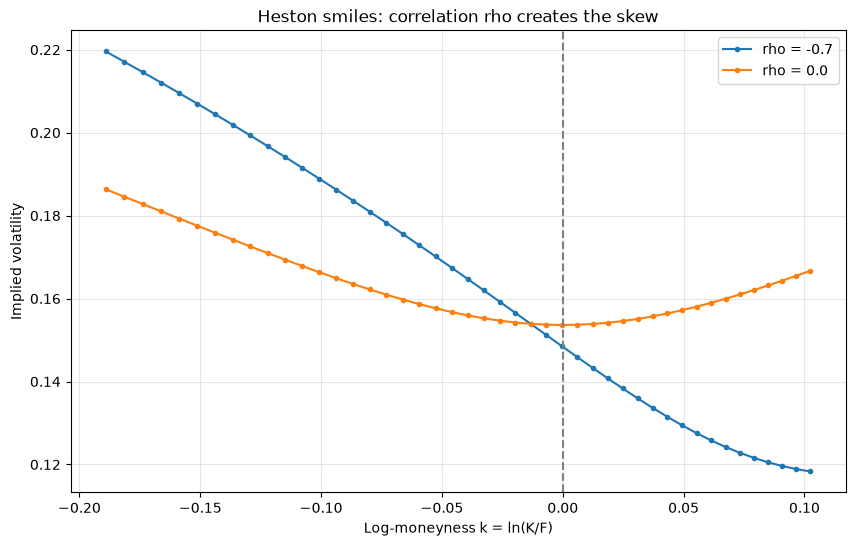

In [5]:
strikes = np.arange(650, 875, 5)

plt.figure(figsize=(10, 6))
for rho in [-0.7, 0.0]:
    ivs = []
    for K in strikes:
        option_type = "put" if K < F else "call"  # OTM options, as in the data
        price = heston_price(F, K, T, r, 0.0225, 2.0, 0.04, 0.6, rho, option_type)
        ivs.append(implied_vol(price, F, K, T, r, option_type))
    plt.plot(np.log(strikes / F), ivs, marker="o", markersize=3, label=f"rho = {rho}")

plt.axvline(0, color="grey", linestyle="--")
plt.xlabel("Log-moneyness k = ln(K/F)")
plt.ylabel("Implied volatility")
plt.title("Heston smiles: correlation rho creates the skew")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

With ρ = 0 the smile is symmetric: vol of vol alone just fattens both tails. With ρ = -0.7, vol rises when the price falls, so the left tail gets much fatter and the smile tilts into the skew we see in SPY. ρ is the skew parameter.

Test 3: simulate the Heston dynamics directly with Monte Carlo and check the prices agree with the formula. I use Euler steps with "full truncation" (negative variance is treated as zero inside each step).

In [6]:
F = 785.28
T = 0.4767
r = 0.0396
v0, kappa, theta, xi, rho = 0.0225, 2.0, 0.04, 0.6, -0.7

rng = np.random.default_rng(0)
n_paths = 200000
n_steps = 250
dt = T / n_steps

x = np.zeros(n_paths)  # log return, ln(F_t / F)
v = np.full(n_paths, v0)
for step in range(n_steps):
    z1 = rng.standard_normal(n_paths)
    z2 = rho * z1 + np.sqrt(1 - rho**2) * rng.standard_normal(n_paths)  # correlated with z1
    v_pos = np.maximum(v, 0)  # full truncation
    x = x - 0.5 * v_pos * dt + np.sqrt(v_pos * dt) * z1
    v = v + kappa * (theta - v_pos) * dt + xi * np.sqrt(v_pos * dt) * z2

F_T = F * np.exp(x)
print(f"Average F_T / F: {F_T.mean() / F:.4f}   (should be close to 1: the forward is a martingale)")

D = np.exp(-r * T)
for K, option_type in [(650, "put"), (700, "put"), (785, "call"), (870, "call")]:
    if option_type == "call":
        payoff = np.maximum(F_T - K, 0)
    else:
        payoff = np.maximum(K - F_T, 0)
    mc_price = D * payoff.mean()
    std_error = D * payoff.std() / np.sqrt(n_paths)
    formula = heston_price(F, K, T, r, v0, kappa, theta, xi, rho, option_type)
    z = (formula - mc_price) / std_error  # within +/-2 means they agree
    print(f"K = {K} {option_type:4s}  formula {formula:8.4f}   Monte Carlo {mc_price:8.4f} +/- {std_error:.4f}   gap in std errors {z:5.2f}")

Average F_T / F: 1.0003   (should be close to 1: the forward is a martingale)
K = 650 put   formula   5.3976   Monte Carlo   5.3834 +/- 0.0575   gap in std errors  0.25
K = 700 put   formula  10.5651   Monte Carlo  10.5533 +/- 0.0817   gap in std errors  0.14
K = 785 call  formula  31.6418   Monte Carlo  31.7768 +/- 0.0875   gap in std errors -1.54
K = 870 call  formula   3.3199   Monte Carlo   3.3436 +/- 0.0316   gap in std errors -0.75


All four gaps are within 2 standard errors, so the formula and the simulation agree.

The calibration will price hundreds of options on every attempt, and calling quad once per option is too slow. quad_vec integrates many functions at once, so I price all strikes of one expiry in a single integral. It must give the same prices as the slow version.

In [7]:
def heston_calls_one_expiry(F, strikes, T, r, v0, kappa, theta, xi, rho):
    k = np.log(strikes / F)
    def integrand(u):
        # the characteristic function doesn't depend on the strike, so compute it once
        phi1 = heston_cf(u - 1j, T, v0, kappa, theta, xi, rho)
        phi2 = heston_cf(u, T, v0, kappa, theta, xi, rho)
        wave = np.exp(-1j * u * k)
        part1 = (wave * phi1 / (1j * u)).real
        part2 = (wave * phi2 / (1j * u)).real
        return np.concatenate([part1, part2])
    integrals = quad_vec(integrand, 0, np.inf, epsabs=1e-6, epsrel=1e-6)[0]
    n = len(strikes)
    P1 = 0.5 + integrals[:n] / np.pi
    P2 = 0.5 + integrals[n:] / np.pi
    D = np.exp(-r * T)
    return D * (F * P1 - strikes * P2)


F = 785.28
T = 0.4767
r = 0.0396
test_strikes = np.array([650.0, 700.0, 785.0, 870.0])
fast = heston_calls_one_expiry(F, test_strikes, T, r, 0.0225, 2.0, 0.04, 0.6, -0.7)
for K, price in zip(test_strikes, fast):
    slow = heston_price(F, K, T, r, 0.0225, 2.0, 0.04, 0.6, -0.7, "call")
    print(f"K = {K:.0f}   fast {price:.6f}   slow {slow:.6f}   gap {price - slow:.2e}")

K = 650   fast 138.147811   slow 138.147811   gap 4.55e-13
K = 700   fast 94.250363   slow 94.250363   gap -9.95e-14
K = 785   fast 31.641844   slow 31.641844   gap 0.00e+00
K = 870   fast 3.319883   slow 3.319883   gap -9.77e-14


Identical to about 1e-13.

Calibration set-up. I fit to 20 options per expiry, spread evenly across each smile (480 in total), and keep the other 2,698 as a test set, like a train/test split in ISLP. If the test error is close to the training error, the model really describes the market rather than memorising 480 points.

Errors are measured in vol points, not dollars: a $0.50 error is huge for a $1 option and nothing for an $80 one. Price error divided by vega (∂C/∂σ) is approximately the error in implied vol, and it's much cheaper than inverting every model price.

In [8]:
keep = []
for expiry, group in options.groupby("expiry"):
    group = group.sort_values("k")
    positions = np.unique(np.linspace(0, len(group) - 1, 20).round().astype(int))  # 20 evenly spaced rows
    keep.extend(group.index[positions])
calib = options.loc[keep].reset_index(drop=True)

# vega = D F n(d1) sqrt(T), at each option's market vol
d1 = (np.log(calib["F"] / calib["strike"]) + 0.5 * calib["iv"]**2 * calib["T"]) / (calib["iv"] * np.sqrt(calib["T"]))
calib["vega"] = np.exp(-calib["r"] * calib["T"]) * calib["F"] * norm.pdf(d1) * np.sqrt(calib["T"])

print("Calibration set:", calib.shape[0], "options from", calib["expiry"].nunique(), "expiries")
print(calib[["expiry", "type", "strike", "k", "iv", "mid", "vega"]].head())

Calibration set: 480 options from 24 expiries
      expiry type  strike         k        iv    mid      vega
0 2026-10-15  put   680.0 -0.129001  0.356311  0.050  1.312914
1 2026-10-15  put   710.0 -0.085828  0.263559  0.085  2.576581
2 2026-10-15  put   724.0 -0.066302  0.221500  0.125  3.995376
3 2026-10-15  put   730.0 -0.058049  0.203932  0.155  5.017122
4 2026-10-15  put   734.0 -0.052584  0.191069  0.175  5.773836


In [9]:
def heston_model_prices(params, data):
    v0, kappa, theta, xi, rho = params
    prices = np.zeros(len(data))
    for expiry, group in data.groupby("expiry"):
        F = group["F"].iloc[0]
        T = group["T"].iloc[0]
        r = group["r"].iloc[0]
        strikes = group["strike"].to_numpy()
        calls = heston_calls_one_expiry(F, strikes, T, r, v0, kappa, theta, xi, rho)
        puts = calls - np.exp(-r * T) * (F - strikes)
        is_call = group["type"].to_numpy() == "call"
        prices[group.index] = np.where(is_call, calls, puts)
    return prices


def heston_residuals(params):
    # price error / vega = error in vol units, one per option
    model = heston_model_prices(params, calib)
    return (model - calib["mid"].to_numpy()) / calib["vega"].to_numpy()


# starting guess from notebook 3: v0 = (1-week ATM vol)^2, theta = (2-year ATM vol)^2
start = [0.012, 2.0, 0.035, 1.0, -0.7]

t0 = time.time()
errors = heston_residuals(start)
seconds = time.time() - t0
print(f"One evaluation of all {len(calib)} options took {seconds:.2f} seconds")
print(f"Starting guess: RMSE = {np.sqrt(np.mean(errors**2)) * 100:.2f} vol points")

One evaluation of all 480 options took 2.19 seconds
Starting guess: RMSE = 3.34 vol points


The fit: least_squares searches for the five parameters that minimise the sum of squared vol errors. It works out how each error responds to a small change in each parameter (the Jacobian), approximates the problem as a linear regression around the current point, takes a step, and repeats, never stepping further than it trusts that approximation (a trust region). x_scale="jac" rescales the parameters, since κ is in the units and v0 in the hundredths.

In [10]:
lower = [0.0001, 0.01, 0.0001, 0.01, -0.999]  # v0, kappa, theta, xi, rho
upper = [1.0, 20.0, 1.0, 3.0, 0.999]

t0 = time.time()
fit = least_squares(heston_residuals, start, bounds=(lower, upper), x_scale="jac", verbose=2)
print(f"Fit took {(time.time() - t0) / 60:.1f} minutes")

v0, kappa, theta, xi, rho = fit.x
np.save("heston_params.npy", fit.x)

print(f"v0    = {v0:.4f}   (today's vol      = {np.sqrt(v0):.1%})")
print(f"kappa = {kappa:.3f}")
print(f"theta = {theta:.4f}   (long-run vol     = {np.sqrt(theta):.1%})")
print(f"xi    = {xi:.3f}")
print(f"rho   = {rho:.3f}")

# Feller condition: variance can never touch zero if it holds
print(f"Feller: 2*kappa*theta = {2 * kappa * theta:.3f}  vs  xi^2 = {xi**2:.3f}  ->  holds: {2 * kappa * theta > xi**2}")

for name, value, lo, hi in zip(["v0", "kappa", "theta", "xi", "rho"], fit.x, lower, upper):
    if value < lo + 0.01 * (hi - lo) or value > hi - 0.01 * (hi - lo):
        print(f"WARNING: {name} = {value:.4f} is at its bound")

rmse = np.sqrt(np.mean(fit.fun**2)) * 100
print(f"RMSE: start 3.34 -> fitted {rmse:.2f} vol points")

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         2.6780e-01                                    1.86e+01    
       1              2         3.9417e-02      2.28e-01       4.65e-01       6.25e-02    
       2              4         3.2398e-02      7.02e-03       3.65e-01       6.01e-02    
       3              5         2.8865e-02      3.53e-03       1.31e+00       1.80e+00    
       4              6         2.3877e-02      4.99e-03       1.18e+00       3.94e-01    
       5              7         2.2543e-02      1.33e-03       1.22e+00       3.68e-01    
       6              8         2.2037e-02      5.05e-04       7.90e-01       9.13e-02    
       7              9         2.1892e-02      1.46e-04       5.10e-01       3.32e-02    
       8             10         2.1849e-02      4.31e-05       2.90e-01       1.03e-02    
       9             11         2.1837e-02      1.22e-05       1.59e-01       4.40e-03    

The error drops from 3.34 to 0.95 vol points. The parameters tell a story: today's vol 10.8% is well below the long-run 21.2%, which is the upward term structure from notebook 3. ρ = -0.69 gives the skew. But κ = 8.3 and ξ = 2.1 are very large, and the Feller condition fails. To produce the steep short-dated skew, Heston needs extreme vol of vol, so variance hits zero often. The fit is good, but the parameters are fitting devices more than a believable description of how SPY volatility moves.

0.95 is the average over the 480 training options and uses the vega approximation. Next I price all 3,178 options, invert each price into an exact implied vol, and compare training and test errors.

In [11]:
t0 = time.time()
options["heston_price"] = heston_model_prices(fit.x, options)
options["heston_iv"] = [
    implied_vol(price, F, K, T, r, option_type)
    for price, F, K, T, r, option_type in zip(options["heston_price"], options["F"], options["strike"], options["T"], options["r"], options["type"])
]
options["vol_error"] = (options["heston_iv"] - options["iv"]) * 100  # exact error, in vol points
print(f"Priced all {len(options)} options in {time.time() - t0:.0f} seconds; model vol not found for {options['heston_iv'].isna().sum()}")

options["in_calib"] = options.index.isin(keep)

def rmse(e): return np.sqrt(np.mean(e.dropna()**2))

train = options[options["in_calib"]].groupby("expiry")["vol_error"].apply(rmse)
test = options[~options["in_calib"]].groupby("expiry")["vol_error"].apply(rmse)
days = options.groupby("expiry")["T"].first() * 365
table = pd.DataFrame({"days": days.round(0).astype(int), "train RMSE": train.round(2), "test RMSE": test.round(2)})
print(table.to_string())
print(f"Overall: train {rmse(options.loc[options['in_calib'], 'vol_error']):.2f}   test {rmse(options.loc[~options['in_calib'], 'vol_error']):.2f} vol points   ({(~options['in_calib']).sum()} test options)")

Priced all 3178 options in 20 seconds; model vol not found for 0
            days  train RMSE  test RMSE
expiry                                 
2026-10-15     7        1.91       1.41
2026-10-16     8        2.61       2.12
2026-10-23    15        2.75       2.28
2026-10-30    22        2.43       1.93
2026-11-06    29        2.22       1.96
2026-11-13    36        1.60       1.44
2026-11-20    43        1.48       1.35
2026-11-30    53        0.99       0.89
2026-12-18    71        0.88       0.83
2026-12-31    84        0.66       0.63
2027-01-15    99        0.62       0.62
2027-01-29   113        0.65       0.63
2027-02-26   141        0.57       0.56
2027-03-19   162        0.50       0.49
2027-03-31   174        0.54       0.53
2027-06-17   252        0.30       0.28
2027-06-30   265        0.38       0.36
2027-09-17   344        0.28       0.24
2027-09-30   357        0.26       0.22
2027-12-17   435        0.35       0.32
2028-01-21   470        0.33       0.30
2028-06-16   61

Train 1.27, test 1.11: no overfitting. (The exact training error is a bit above 0.95 because vega only approximates the vol error.) The error is almost all at the short end: about 2 to 2.6 vol points for the first three weeks, and under 0.6 beyond three months.

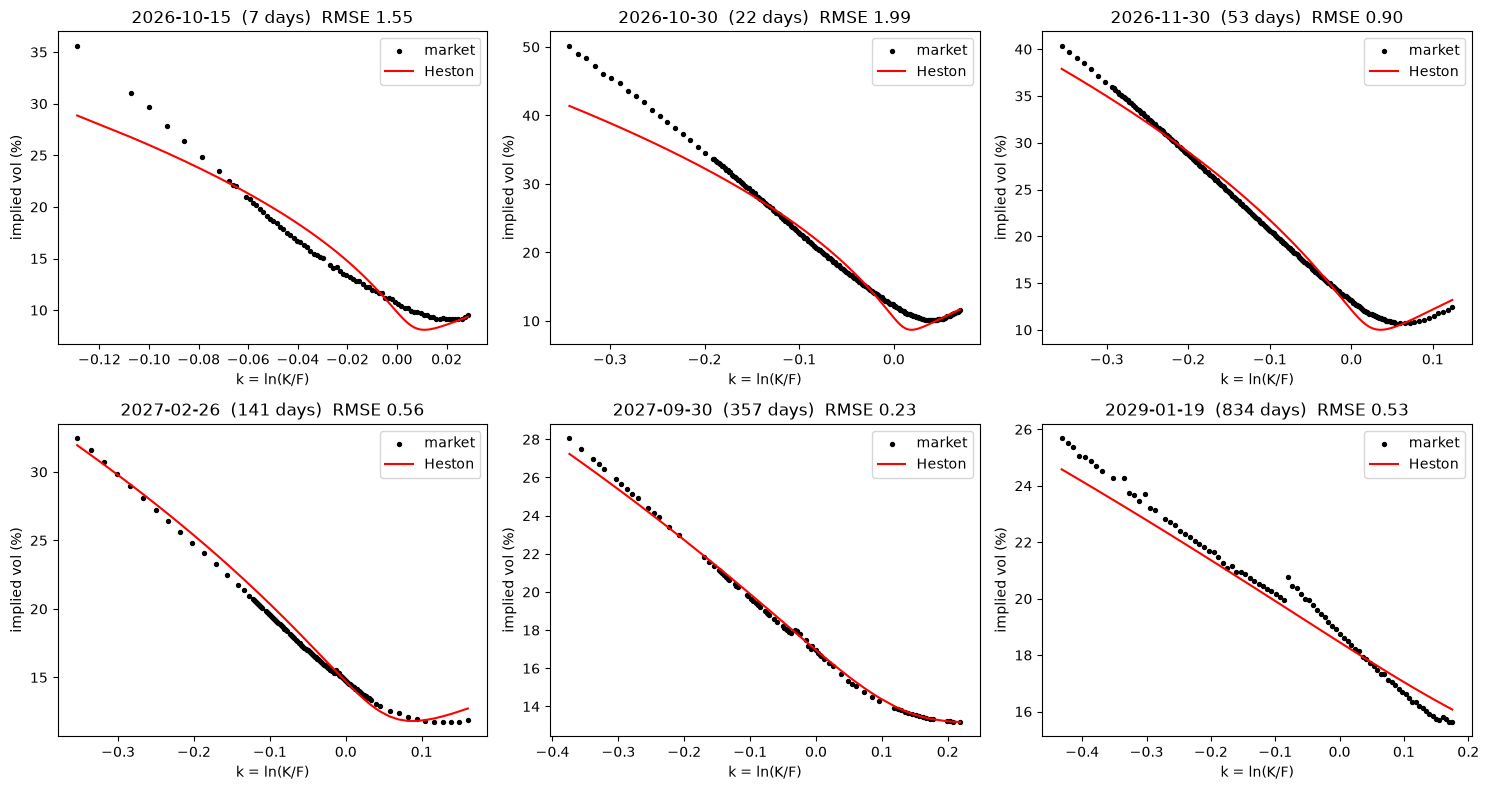

In [12]:
expiries = sorted(options["expiry"].unique())
chosen = [expiries[i] for i in [0, 3, 7, 12, 18, 23]]  # shortest to longest

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, expiry in zip(axes.flatten(), chosen):
    group = options[options["expiry"] == expiry].sort_values("k")
    ax.scatter(group["k"], group["iv"] * 100, s=8, color="black", label="market")
    ax.plot(group["k"], group["heston_iv"] * 100, color="red", label="Heston")
    error = rmse(group["vol_error"])
    ax.set_title(f"{pd.Timestamp(expiry).date()}  ({group['T'].iloc[0] * 365:.0f} days)  RMSE {error:.2f}")
    ax.set_xlabel("k = ln(K/F)")
    ax.set_ylabel("implied vol (%)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/06_heston_fit.png", dpi=150)
plt.show()

The 7-day smile shows the problem: the market's skew is steeper than anything Heston can produce at one week. In Heston, volatility moves continuously, so over a few days the price can't move far enough to justify the market's prices for deep puts. That's the classic motivation for adding jumps.

## Merton
Merton's model is Black-Scholes plus jumps. Jumps arrive at rate λ per year (Poisson), and each multiplies the price by e^J with J ~ N(μJ, δ²). Conditioning on the number of jumps n, the price is lognormal again, so the option price is a Poisson-weighted sum of Black-Scholes prices, each with its own forward F_n and vol σ_n. The forward is shifted by e^(-λmT) so that F_T still averages to F.

In [13]:
def merton_calls_one_expiry(F, strikes, T, r, sigma, lam, muJ, delta):
    m = np.exp(muJ + 0.5 * delta**2) - 1  # average jump, as a percentage
    calls = np.zeros(len(strikes))
    for n in range(60):  # 60 or more jumps has essentially zero probability
        weight = poisson.pmf(n, lam * T)
        F_n = F * np.exp(-lam * m * T) * (1 + m)**n
        sigma_n = np.sqrt(sigma**2 + n * delta**2 / T)
        calls += weight * bs_price(F_n, strikes, T, r, sigma_n, "call")
    return calls


# Test 1: with no jumps it must be exactly Black-Scholes
F = 785.28
T = 0.4767
r = 0.0396
test_strikes = np.array([650.0, 700.0, 785.0, 870.0])
merton = merton_calls_one_expiry(F, test_strikes, T, r, 0.15, 0.0, -0.10, 0.08)
bs = bs_price(F, test_strikes, T, r, 0.15, "call")
print("Test 1: no jumps (lambda = 0) must equal Black-Scholes")
for K, a, b in zip(test_strikes, merton, bs):
    print(f"K = {K:.0f}   Merton {a:.6f}   BS {b:.6f}   gap {a - b:.2e}")

Test 1: no jumps (lambda = 0) must equal Black-Scholes
K = 650   Merton 133.720832   BS 133.720832   gap 0.00e+00
K = 700   Merton 88.749522   BS 88.749522   gap 0.00e+00
K = 785   Merton 31.955992   BS 31.955992   gap 0.00e+00
K = 870   Merton 7.136893   BS 7.136893   gap 0.00e+00


Test 2: simulate the model directly. Per path: draw the number of jumps, then the sum of their sizes, then the normal diffusion part.

In [14]:
sigma, lam, muJ, delta = 0.12, 0.5, -0.10, 0.08
rng = np.random.default_rng(1)
n_paths = 1_000_000

m = np.exp(muJ + 0.5 * delta**2) - 1
n_jumps = rng.poisson(lam * T, n_paths)
# the sum of n normal jumps is normal with mean n*muJ and std delta*sqrt(n)
jump_sum = muJ * n_jumps + delta * np.sqrt(n_jumps) * rng.standard_normal(n_paths)
diffusion = -0.5 * sigma**2 * T + sigma * np.sqrt(T) * rng.standard_normal(n_paths)
F_T = F * np.exp(-lam * m * T + diffusion + jump_sum)
print(f"Average F_T / F = {F_T.mean() / F:.4f}  (should be close to 1)")

calls = merton_calls_one_expiry(F, test_strikes, T, r, sigma, lam, muJ, delta)
for K, call in zip(test_strikes, calls):
    # out-of-the-money options, like the market data
    if K < F:
        formula = call - np.exp(-r * T) * (F - K)
        payoff = np.exp(-r * T) * np.maximum(K - F_T, 0)
        name = "put "
    else:
        formula = call
        payoff = np.exp(-r * T) * np.maximum(F_T - K, 0)
        name = "call"
    mc = payoff.mean()
    se = payoff.std() / np.sqrt(n_paths)
    print(f"K = {K:.0f} {name}   formula {formula:.4f}   MC {mc:.4f} +/- {se:.4f}   z = {(formula - mc) / se:.2f}")

Average F_T / F = 1.0001  (should be close to 1)
K = 650 put    formula 2.1341   MC 2.1275 +/- 0.0126   z = 0.52
K = 700 put    formula 6.2837   MC 6.2719 +/- 0.0225   z = 0.53
K = 785 put    formula 30.2287   MC 30.1592 +/- 0.0475   z = 1.46
K = 870 call   formula 5.1835   MC 5.1950 +/- 0.0182   z = -0.63


All within 2 standard errors. Test 3: what do jumps do to the smile, at 1 month and at 1 year?

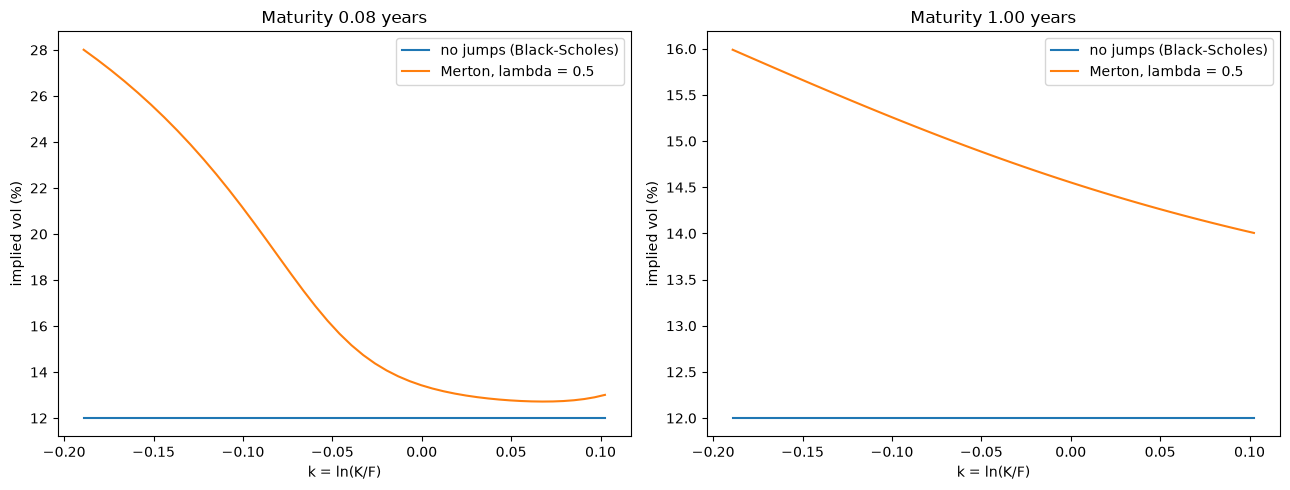

In [15]:
strikes = np.arange(650, 875, 5.0)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, T_plot in zip(axes, [1 / 12, 1.0]):
    for lam_plot, label in [(0.0, "no jumps (Black-Scholes)"), (0.5, "Merton, lambda = 0.5")]:
        calls = merton_calls_one_expiry(F, strikes, T_plot, r, 0.12, lam_plot, -0.10, 0.08)
        ivs = [implied_vol(c, F, K, T_plot, r, "call") for c, K in zip(calls, strikes)]
        ax.plot(np.log(strikes / F), np.array(ivs) * 100, label=label)
    ax.set_title(f"Maturity {T_plot:.2f} years")
    ax.set_xlabel("k = ln(K/F)")
    ax.set_ylabel("implied vol (%)")
    ax.legend()
plt.tight_layout()
plt.show()

At 1 month the jumps create a very steep skew (12% to 28%), exactly what Heston couldn't do. At 1 year the skew is much flatter, because over a long horizon many small diffusion moves dominate a few jumps. So Merton should be strong at the short end and weak at the long end, the opposite of Heston.

Same calibration as for Heston: the same 480 options and the same vega-weighted errors. The bounds keep the jumps economically sensible. With wide bounds, an earlier test chose a -95% crash once every 50 years, which fits the numbers but means nothing. I also start from two different points and keep the better fit, to check it isn't stuck in a local minimum.

In [16]:
def merton_model_prices(params, data):
    sigma, lam, muJ, delta = params
    prices = np.zeros(len(data))
    for expiry, group in data.groupby("expiry"):
        F = group["F"].iloc[0]
        T = group["T"].iloc[0]
        r = group["r"].iloc[0]
        strikes = group["strike"].to_numpy()
        calls = merton_calls_one_expiry(F, strikes, T, r, sigma, lam, muJ, delta)
        puts = calls - np.exp(-r * T) * (F - strikes)
        is_call = group["type"].to_numpy() == "call"
        prices[group.index] = np.where(is_call, calls, puts)
    return prices


def merton_residuals(params):
    model = merton_model_prices(params, calib)
    return (model - calib["mid"].to_numpy()) / calib["vega"].to_numpy()


merton_lower = [0.01, 0.05, -0.5, 0.01]  # sigma, lam, muJ, delta
merton_upper = [1.0, 5.0, 0.2, 0.5]
# rare medium-sized crashes, and frequent small jumps
starts = [[0.10, 0.5, -0.10, 0.10], [0.10, 2.0, -0.05, 0.05]]

t0 = time.time()
start_errors = merton_residuals(starts[0])
print(f"One evaluation took {time.time() - t0:.2f} seconds")

merton_fit = None
for start_point in starts:
    t0 = time.time()
    attempt = least_squares(merton_residuals, start_point, bounds=(merton_lower, merton_upper), x_scale="jac")
    attempt_rmse = np.sqrt(np.mean(attempt.fun**2)) * 100
    print(f"start {start_point} -> {np.round(attempt.x, 4)}   RMSE {attempt_rmse:.2f}   ({time.time() - t0:.0f} s)")
    if merton_fit is None or attempt.cost < merton_fit.cost:
        merton_fit = attempt

sigma, lam, muJ, delta = merton_fit.x
np.save("merton_params.npy", merton_fit.x)
m = np.exp(muJ + 0.5 * delta**2) - 1

print()
print(f"sigma = {sigma:.4f}   (diffusion vol between jumps = {sigma:.1%})")
print(f"lam   = {lam:.3f}   (one jump every {1 / lam:.1f} years on average)")
print(f"muJ   = {muJ:.4f}   (typical jump = {np.exp(muJ) - 1:.1%})")
print(f"delta = {delta:.4f}   (jump size spread)")
print(f"average jump m = {m:.1%}")

for name, value, lo, hi in zip(["sigma", "lam", "muJ", "delta"], merton_fit.x, merton_lower, merton_upper):
    if np.isclose(value, lo, rtol=0.01, atol=1e-6) or np.isclose(value, hi, rtol=0.01, atol=1e-6):
        print(f"WARNING: {name} = {value:.4f} is at its bound")

print(f"RMSE: Heston {np.sqrt(np.mean(fit.fun**2)) * 100:.2f}   Merton {np.sqrt(np.mean(merton_fit.fun**2)) * 100:.2f} vol points")

One evaluation took 0.79 seconds
start [0.1, 0.5, -0.1, 0.1] -> [ 0.1261  0.1038 -0.2944  0.1866]   RMSE 2.94   (81 s)
start [0.1, 2.0, -0.05, 0.05] -> [ 0.1261  0.1039 -0.2944  0.1866]   RMSE 2.94   (92 s)

sigma = 0.1261   (diffusion vol between jumps = 12.6%)
lam   = 0.104   (one jump every 9.6 years on average)
muJ   = -0.2944   (typical jump = -25.5%)
delta = 0.1866   (jump size spread)
average jump m = -24.2%
RMSE: Heston 0.95   Merton 2.94 vol points


Both starts land on the same answer: 12.6% normal vol, plus a crash of about -25% roughly once every 10 years. That is a believable picture of the S&P 500. But the error is 2.94 vol points, three times Heston's 0.95. Now the out-of-sample comparison, by expiry and by moneyness.

In [17]:
t0 = time.time()
options["merton_price"] = merton_model_prices(merton_fit.x, options)
options["merton_iv"] = [
    implied_vol(price, F, K, T, r, option_type)
    for price, F, K, T, r, option_type in zip(options["merton_price"], options["F"], options["strike"], options["T"], options["r"], options["type"])
]
options["merton_error"] = (options["merton_iv"] - options["iv"]) * 100
print(f"Priced all {len(options)} options with Merton in {time.time() - t0:.0f} seconds; model vol not found for {options['merton_iv'].isna().sum()}")

test_set = options[~options["in_calib"]]  # options neither model was fitted to

by_expiry = pd.DataFrame({
    "days": (test_set.groupby("expiry")["T"].first() * 365).round(0).astype(int),
    "Heston": test_set.groupby("expiry")["vol_error"].apply(rmse).round(2),
    "Merton": test_set.groupby("expiry")["merton_error"].apply(rmse).round(2),
})
by_expiry["winner"] = np.where(by_expiry["Heston"] <= by_expiry["Merton"], "Heston", "Merton")
print("\nTest RMSE by expiry (vol points)")
print(by_expiry.to_string())

buckets = pd.cut(test_set["k"], bins=[-1.0, -0.20, -0.10, -0.03, 0.03, 0.10, 1.0],
                 labels=["deep puts (k<-0.20)", "puts (-0.20 to -0.10)", "near puts (-0.10 to -0.03)", "ATM (-0.03 to 0.03)", "near calls (0.03 to 0.10)", "calls (k>0.10)"])
short = test_set["T"] < 60 / 365
by_k = pd.DataFrame({
    "count": test_set.groupby(buckets, observed=False)["k"].count(),
    "Heston": test_set.groupby(buckets, observed=False)["vol_error"].apply(rmse).round(2),
    "Merton": test_set.groupby(buckets, observed=False)["merton_error"].apply(rmse).round(2),
    "Heston <60d": test_set[short].groupby(buckets[short], observed=False)["vol_error"].apply(rmse).round(2),
    "Merton <60d": test_set[short].groupby(buckets[short], observed=False)["merton_error"].apply(rmse).round(2),
})
print("\nTest RMSE by moneyness (vol points); last two columns: expiries under 60 days only")
print(by_k.to_string())

print(f"\nOverall test RMSE:  Heston {rmse(test_set['vol_error']):.2f}   Merton {rmse(test_set['merton_error']):.2f} vol points")

Priced all 3178 options with Merton in 19 seconds; model vol not found for 0

Test RMSE by expiry (vol points)
            days  Heston  Merton  winner
expiry                                  
2026-10-15     7    1.41    2.58  Heston
2026-10-16     8    2.12    2.83  Heston
2026-10-23    15    2.28    3.25  Heston
2026-10-30    22    1.93    2.54  Heston
2026-11-06    29    1.96    1.83  Merton
2026-11-13    36    1.44    1.54  Heston
2026-11-20    43    1.35    1.40  Heston
2026-11-30    53    0.89    1.23  Heston
2026-12-18    71    0.83    1.64  Heston
2026-12-31    84    0.63    1.69  Heston
2027-01-15    99    0.62    1.78  Heston
2027-01-29   113    0.63    2.06  Heston
2027-02-26   141    0.56    1.89  Heston
2027-03-19   162    0.49    2.23  Heston
2027-03-31   174    0.53    2.77  Heston
2027-06-17   252    0.28    2.73  Heston
2027-06-30   265    0.36    2.90  Heston
2027-09-17   344    0.24    3.11  Heston
2027-09-30   357    0.22    3.08  Heston
2027-12-17   435    0.32    

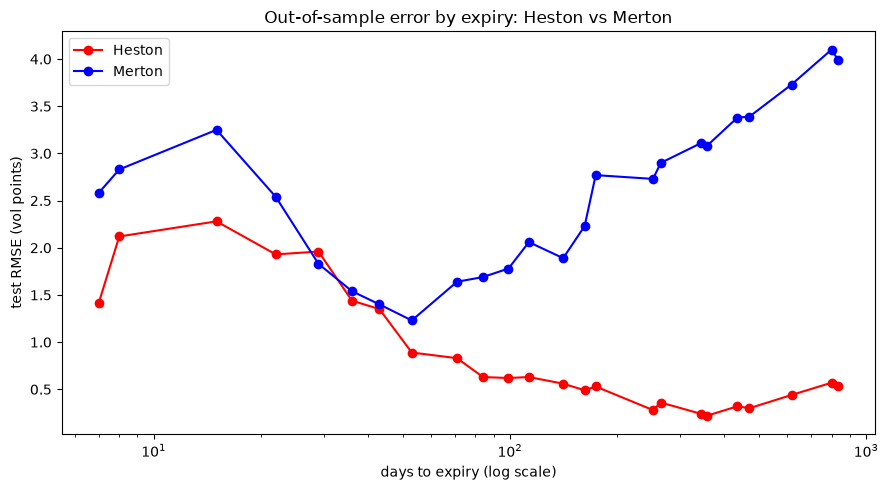

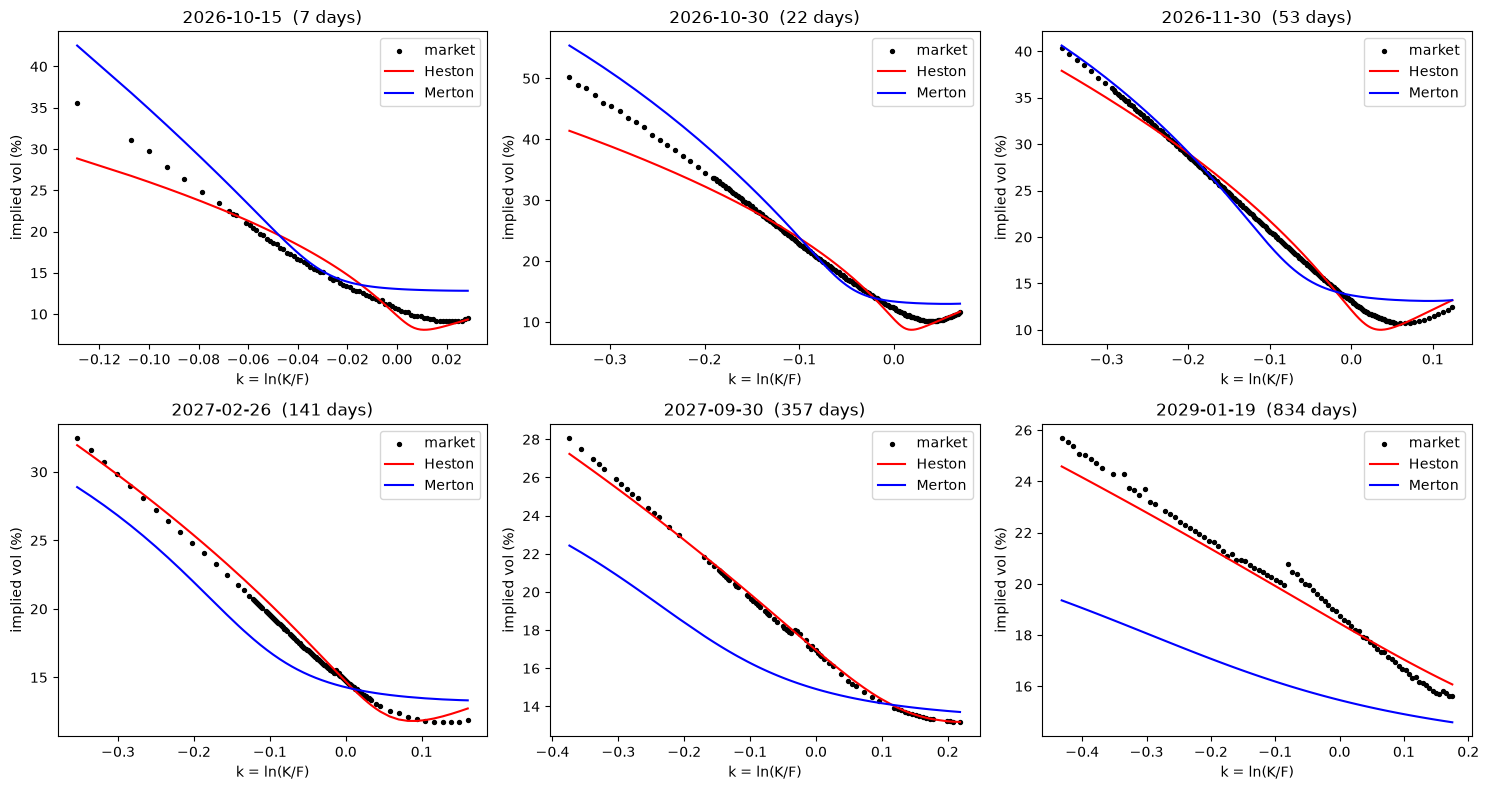

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(by_expiry["days"], by_expiry["Heston"], marker="o", color="red", label="Heston")
ax.plot(by_expiry["days"], by_expiry["Merton"], marker="o", color="blue", label="Merton")
ax.set_xscale("log")
ax.set_xlabel("days to expiry (log scale)")
ax.set_ylabel("test RMSE (vol points)")
ax.set_title("Out-of-sample error by expiry: Heston vs Merton")
ax.legend()
plt.tight_layout()
plt.savefig("figures/07_error_by_expiry.png", dpi=150)
plt.show()

expiries = sorted(options["expiry"].unique())
chosen = [expiries[i] for i in [0, 3, 7, 12, 18, 23]]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, expiry in zip(axes.flatten(), chosen):
    group = options[options["expiry"] == expiry].sort_values("k")
    ax.scatter(group["k"], group["iv"] * 100, s=8, color="black", label="market")
    ax.plot(group["k"], group["heston_iv"] * 100, color="red", label="Heston")
    ax.plot(group["k"], group["merton_iv"] * 100, color="blue", label="Merton")
    ax.set_title(f"{pd.Timestamp(expiry).date()}  ({group['T'].iloc[0] * 365:.0f} days)")
    ax.set_xlabel("k = ln(K/F)")
    ax.set_ylabel("implied vol (%)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/08_heston_vs_merton_smiles.png", dpi=150)
plt.show()

Heston wins clearly: 1.11 vs 2.47 vol points out of sample, and it is better at 23 of the 24 expiries. Merton is the better model only in one corner: deep puts on expiries under 60 days (2.85 vs 3.35), where jumps do the job Heston's continuous volatility can't.

Merton's weakness is the long end. Its jump effect fades with maturity and it has no way to make vol rise over time, so it can't produce the upward term structure (one diffusion vol has to fit both 1 week and 2 years). Heston's mean reversion handles that naturally.

The obvious next step would be a model with both, stochastic vol plus jumps (Bates, 1996), which is the standard answer to exactly this trade-off.

In [19]:
options.to_csv("spy_model_fits_2026-10-08.csv", index=False)
by_expiry.to_csv("model_error_by_expiry.csv")
by_k.to_csv("model_error_by_moneyness.csv")

params = pd.DataFrame({
    "Heston": pd.Series(fit.x, index=["v0", "kappa", "theta", "xi", "rho"]),
    "Merton": pd.Series(merton_fit.x, index=["sigma", "lam", "muJ", "delta"]),
})
params.to_csv("model_params.csv")
print(params)

         Heston    Merton
delta       NaN  0.186596
kappa  8.348972       NaN
lam         NaN  0.103830
muJ         NaN -0.294435
rho   -0.687441       NaN
sigma       NaN  0.126118
theta  0.044820       NaN
v0     0.011579       NaN
xi     2.099503       NaN
